# RT-DETR-L (Ultralytics) — Training

Fine-tunes the COCO-pretrained `rtdetr-l.pt` on Construction Site Safety. The test-set evaluation is in
[`rtdetr_l_eval.ipynb`](rtdetr_l_eval.ipynb).

| Setting | Value |
|---|---|
| Input size | 640×640 |
| Optimizer, LR schedule, loss | Ultralytics defaults for this model (`optimizer="auto"`) |
| Batch size | 8 |
| Epochs | 10 (scratch run; training runs use up to `MAX_EPOCHS` = 200) |
| Early stopping | patience 15 on validation mAP@50-95 |
| Checkpoint | best validation fitness → `models/rtdetr_l/weights/best.pt` |

> **Scratch run.** `EPOCHS` is set to **10** in the hyperparameter cell so the notebook runs end to end quickly; use
> a higher value such as `MAX_EPOCHS` (200) for training runs.

**Data augmentation** is Ultralytics' default pipeline with mosaic turned off (`ULTRALYTICS_AUGMENTATION` in
`ultralytics_adapter.py`): horizontal flip (p = 0.5), scale ±50 %, translate ±10 %, HSV jitter (hue 0.015, saturation
0.7, value 0.4), and blur / median blur / grayscale / CLAHE at p=0.01 each. Validation and test images are not
augmented. The torchvision models use horizontal flip only.


In [ ]:
import csv
import warnings

%matplotlib inline
import matplotlib.pyplot as plt
from ultralytics import RTDETR

from ppe_detection_evaluation.dataset.core import check_dataset, class_box_counts, download_dataset
from ppe_detection_evaluation.dataset.ultralytics_adapter import ULTRALYTICS_AUGMENTATION, write_ultralytics_yaml
from ppe_detection_evaluation.experiment import DATA_ROOT, IMAGE_SIZE, MAX_EPOCHS, MODELS_DIR, PRETRAINED_DIR, SEED

# RT-DETR's deformable attention uses grid_sample, whose CUDA backward has no deterministic implementation. Training
# keeps deterministic=True for every other op; RT-DETR runs are therefore close to, but not bit-for-bit, reproducible.
warnings.filterwarnings("ignore", message="grid_sampler_2d_backward_cuda does not have a deterministic implementation")

## Hyperparameters

Everything tunable for this model is set in the next cell. `SEED`, `IMAGE_SIZE` and `MAX_EPOCHS` are shared by all four
notebooks (`experiment.py`): the seed makes runs reproducible. Epochs, early stopping, batch size and optimizer settings
are chosen per model.

In [2]:
EPOCHS = 10  # set higher for training runs, such as MAX_EPOCHS
PATIENCE = 15  # epochs without a validation mAP@50-95 improvement
BATCH_SIZE = 8    # RT-DETR-L is memory hungry; batch=-1 lets Ultralytics pick the largest that fits
# Optimizer, LR schedule and loss weights stay at Ultralytics' defaults (optimizer="auto").

In [3]:
# SEED, DATA_ROOT and the model folders come from experiment.py and are shared by all four notebooks.
PROJECT_DIR = MODELS_DIR  # the run lands in models/<RUN_NAME>/ (weights/, curves, results.csv)
RUN_NAME = "rtdetr_l"
print(f"Epochs: {EPOCHS} | Batch: {BATCH_SIZE} | Image size: {IMAGE_SIZE}")

Epochs: 10 | Batch: 8 | Image size: 640


## 1. Dataset

[Construction Site Safety](https://www.kaggle.com/datasets/snehilsanyal/construction-site-safety-image-dataset-roboflow)
(Roboflow, via Kaggle), with all 10 classes. `download_dataset` is a no-op once `data/construction-site-safety` exists,
so all four notebooks share one copy.

In [ ]:
download_dataset(DATA_ROOT)
splits = check_dataset(DATA_ROOT)  # raises if the class order differs from DEFAULT_CLASS_NAMES

counts = {split: class_box_counts(DATA_ROOT, split) for split in splits}
print(f"{'Boxes':<10}" + "".join(f"{split.capitalize():>8}" for split in splits))
for name in counts["train"]:
    print(f"{name:<10}" + "".join(f"{counts[split][name]:>8}" for split in splits))
print("-" * (10 + 8 * len(splits)))
print(f"{'Images':<10}" + "".join(f"{n:>8}" for n in splits.values()))

# Ultralytics resolves relative paths in data.yaml against the CWD, so write one with absolute paths.
data_yaml = write_ultralytics_yaml(DATA_ROOT)

## 2. Model

COCO-pretrained RT-DETR-L. When training starts, Ultralytics rebuilds the model with the dataset's 10 classes and
copies every pretrained tensor whose name and shape match. Only the class-score layers (one for the encoder, one per
decoder layer) and the denoising label embedding start fresh; the backbone, encoder and box heads keep their COCO
weights. RT-DETR has no NMS: the evaluation keeps queries scoring at least 0.001, at most 100 per image.

In [8]:
model = RTDETR(PRETRAINED_DIR / "rtdetr-l.pt")  # COCO weights, downloaded here on first use
model.info()

rt-detr-l summary: 449 layers, 32,970,476 parameters, 0 gradients, 110.2 GFLOPs


(449, 32970476, 0, 110.2435104)

## 3. Training

After training starts, open `train_batch0.jpg` in the run directory: it must show single images, with **no** mosaic
collages.

In [ ]:
model.train(
    data=str(data_yaml),
    epochs=EPOCHS,
    patience=PATIENCE,
    batch=BATCH_SIZE,
    imgsz=IMAGE_SIZE,
    seed=SEED,
    project=str(PROJECT_DIR),
    name=RUN_NAME,
    exist_ok=True,
    **ULTRALYTICS_AUGMENTATION,
)

save_dir = model.trainer.save_dir
print(f"\nResults saved to: {save_dir}")

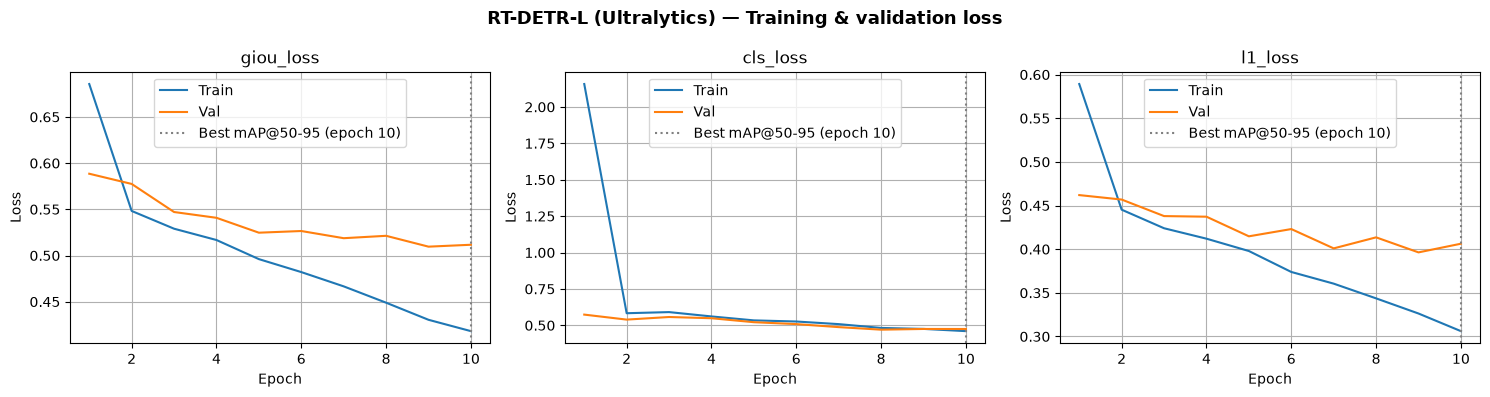

In [10]:
with open(save_dir / "results.csv") as f:
    rows = list(csv.DictReader(f))
history = {key.strip(): [float(row[key]) for row in rows] for key in rows[0]}
epochs_x = history["epoch"]
best_epoch = epochs_x[max(range(len(rows)), key=lambda i: history["metrics/mAP50-95(B)"][i])]

# Loss terms differ per model (e.g. box/cls/l1 for YOLO26, giou/cls/l1 for RT-DETR), so read them from the CSV.
losses = [key.removeprefix("train/") for key in history if key.startswith("train/")]
fig, axes = plt.subplots(1, len(losses), figsize=(5 * len(losses), 4))
for ax, loss in zip(axes, losses):
    ax.plot(epochs_x, history[f"train/{loss}"], label="Train")
    ax.plot(epochs_x, history[f"val/{loss}"], label="Val")
    ax.axvline(best_epoch, color="grey", linestyle=":", lw=1.5, label=f"Best mAP@50-95 (epoch {best_epoch:.0f})")
    ax.set(xlabel="Epoch", ylabel="Loss", title=loss)
    ax.legend()
    ax.grid(True)
plt.suptitle("RT-DETR-L (Ultralytics) — Training & validation loss", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(save_dir / "loss_curves.png", dpi=150)
plt.show()

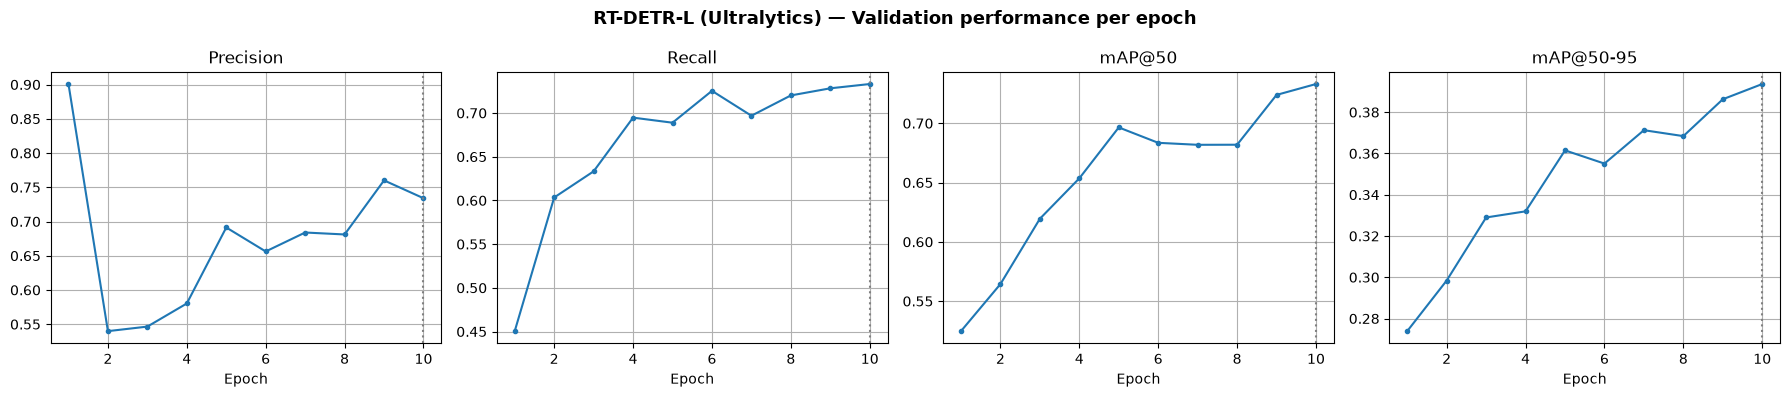

In [11]:
metrics = [
    ("metrics/precision(B)", "Precision"),
    ("metrics/recall(B)", "Recall"),
    ("metrics/mAP50(B)", "mAP@50"),
    ("metrics/mAP50-95(B)", "mAP@50-95"),
]
fig, axes = plt.subplots(1, len(metrics), figsize=(18, 4))
for ax, (key, label) in zip(axes, metrics):
    ax.plot(epochs_x, history[key], marker="o", markersize=3)
    ax.axvline(best_epoch, color="grey", linestyle=":", lw=1.5)
    ax.set(xlabel="Epoch", title=label)
    ax.grid(True)
plt.suptitle("RT-DETR-L (Ultralytics) — Validation performance per epoch", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(save_dir / "val_metrics.png", dpi=150)
plt.show()

Next: evaluate `models/rtdetr_l/weights/best.pt` on the test split with [`rtdetr_l_eval.ipynb`](rtdetr_l_eval.ipynb).